# CRTM-OIS — демонстрація програмного проєкту

**Staged Method and System for Computing the Integral Cyber Resilience of Critical Infrastructure Objects**
(рукопис для *Systems*, MDPI) — програмна реалізація, орієнтована на **агентів** і **нейрорішення**.

Ноутбук проходить увесь ланцюг статті і розширення проєкту:

| § | Зміст | Звідки у статті |
|---|---|---|
| 1 | Сценарій BNK_PAY, кортежі метрик, таблиці класів | §2.1, §2.5, Table A1 |
| 2 | Сім етапів методу на одному прогоні, шина за шиною | §2.2, Table 1, Table 6 |
| 3 | Структурна модель B0–B8, CU, дев’ять шин | §2.3, Fig. 1–2, Tables 2–3 |
| 4 | Перевірка відтворення 15 опублікованих значень | §3.1, Table 5 |
| 5 | П’ять експериментів адекватності, розгортка t | §3.3, Table 7, Fig. 5–6 |
| 6 | Робастність до ваг і контроль некомпенсації | §3.4, Fig. 7 |
| 7 | **Агентний шар**: блоки як агенти на шині повідомлень | розширення |
| 8 | **Нейросурогат** (монотонна MLP) проти точної системи | розширення |
| 9 | **Цифровий двійник + мультиагентний центр**: телеметрія, автоенкодер, прогноз, сторож | розширення §4.2 |
| 10 | **Агент-радник**: точний what-if і план покращення | розширення §4.1, §4.3 |
| 11 | **LLM-аналітик** (інструменти для Claude) і офлайн-звіт | розширення |
| 12 | **Калібрування ваг цілей** за експертними рівнями | майбутня робота §4.5 |

> Дані сценарію — ілюстративні значення з CRTM [37], не польові вимірювання. Експерименти верифікують реалізацію, а не
> валідність оцінок реальних об’єктів. Цифровий двійник і «експерти» в §9 і §12 — синтетичні.

In [1]:
import sys, time, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # корінь проєкту CRTM-OIS
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from crtm_ois import *
from crtm_ois import levels as lv, experiments as ex
from crtm_ois.viz import charts, diagrams
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
cfg = bnk_pay()
print(SOFTWARE_VERSION, "| конфігурація", cfg.version, "| метрик:", cfg.n_metrics, "| дій:", len(cfg.actions))

CRTM-OIS 1.0 | конфігурація cfg-c85ade5a0ea4 | метрик: 39 | дій: 7


## 1. Сценарій і модель метрик
Кожна базова дія β має кортеж дескрипторів: таблиця класів ξ ∈ ℝ⁶, полярність σ, вага, ознака ключової метрики (*).

In [2]:
rows = []
for a in cfg.actions:
    for m in a.metrics:
        rows.append({"goal": a.goal, "action": a.code, "metric": m.code + ("*" if m.core else ""), "name": m.name,
                     "unit": m.unit, "σ": m.sigma, "ξ": m.xi, "w": round(m.weight, 3),
                     "discrete step": m.step, "E1": e1_values()[(a.code, m.code)]})
pd.DataFrame(rows)

,goal,action,metric,name,unit,σ,ξ,w,discrete step,E1
0,ANT,UN.S1.A1,M1*,Number of TI sources used,sources,1,"(0.0, 1.0, 2.0, 3.0, 4.0, 4.0)",0.250,1.00,4.0
1,ANT,UN.S1.A1,M2,TI update frequency,events/day,1,"(1.0, 2.0, 7.0, 25.0, 96.0, 96.0)",0.150,NaN,96.0
2,ANT,UN.S1.A1,M3,Time to determine TI relevance,min,-1,"(180.0, 179.0, 90.0, 30.0, 10.0, 0.0)",0.250,NaN,25.0
3,ANT,UN.S1.A1,M4,Time to disseminate defensive TTPs,min,-1,"(240.0, 239.0, 120.0, 60.0, 15.0, 0.0)",0.200,NaN,45.0
4,ANT,UN.S1.A1,M5,External TI sharing frequency,events/month,1,"(0.0, 1.0, 2.0, 4.0, 9.0, 9.0)",0.050,1.00,4.0
5,ANT,UN.S1.A1,M6,Number of monitored threat types,types,1,"(0.0, 1.0, 2.0, 3.0, 5.0, 5.0)",0.100,1.00,4.0
6,ANT,UN.S2.A1,M1,Time since last MIA/BIA/CJA update,min,-1,"(777600.0, 777599.0, 525600.0, 262080.0, 13104...",0.333,NaN,705600.0
7,ANT,UN.S2.A1,M2,Degree of MIA/BIA/CJA validation,rank,1,"(0.0, 1.0, 2.0, 3.0, 4.0, 4.0)",0.333,1.00,4.0
8,ANT,UN.S2.A1,M3,Resources with assigned criticality,%,1,"(30.0, 31.0, 61.0, 76.0, 91.0, 100.0)",0.333,NaN,80.0
9,WITH,CN.S1.A1,AM-DA-1,Time to assess mission damage,min,-1,"(300.0, 299.0, 180.0, 90.0, 30.0, 0.0)",0.100,NaN,210.0


Анкерована кусково-лінійна нормалізація (4) збігається з таблицею класів за побудовою; лінійне перемасштабування — ні:

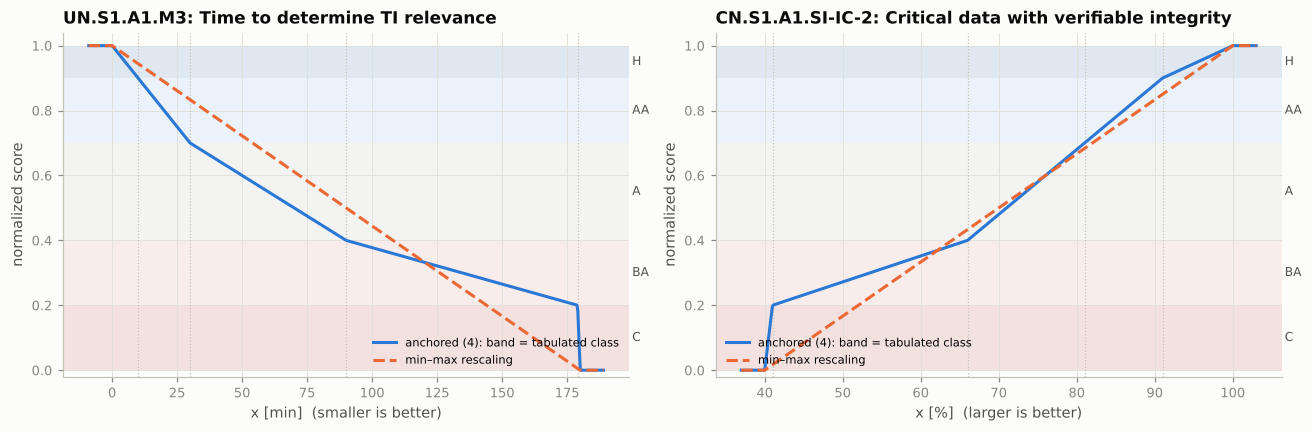

In [3]:
fig = charts.normalization_figure(cfg); plt.show()

## 2. Сім етапів на одному прогоні (стан E1)
Керувальний блок `assess` викликає етапи по черзі; кожен етап повертає запис шини.

In [4]:
r = assess(cfg, e1_values(), n=200_000)
print("trace:", " → ".join(f"{t['bus']}({t['block']})" for t in r.trace.records))
print(f"R = {r.R['R']:.4f} ({r.R['level_name']}),  R_min = {r.R['R_min']:.4f},  [R_L, R_U] = [{r.R['R_L']:.4f}, {r.R['R_U']:.4f}]")
print("стабільний щодо пропусків:", r.R["stable_missing"], "| найслабша ціль:", r.R["weakest_goal"], "| час:", round(r.elapsed_ms,1), "мс")

trace: C(CU) → X(B0) → XiWK(B1) → O(B2) → M(B3) → A(B4) → G(B5) → R(B6) → P(B7) → C(CU)
R = 0.6983 (average),  R_min = 0.5885,  [R_L, R_U] = [0.6909, 0.7034]
стабільний щодо пропусків: False | найслабша ціль: WITH | час: 139.1 мс


Динамічний режим для дії UN.S1.A1 у станах E1 та E2 (Table 6 статті):

In [5]:
st = five_states(cfg)
def table6(e):
    rr = assess(cfg, st[e], robust=False); a = cfg.action("UN.S1.A1")
    d = pd.DataFrame([{"exp": e, "code": m.code + ("*" if m.core else ""), "x (bus X)": st[e][("UN.S1.A1", m.code)],
                       "ξ": m.xi, "m (bus M)": round(rr.norm["M"][("UN.S1.A1", m.code)], 4),
                       "level": lv.code(rr.norm["Lambda"][("UN.S1.A1", m.code)]), "w": m.weight,
                       "w·m": round(m.weight * rr.norm["M"][("UN.S1.A1", m.code)], 4)} for m in a.metrics])
    A = rr.A["UN.S1.A1"]
    print(f"{e}: S = {A['S']:.4f}, c = {A['c']:.2f}, μ = {A['mu']:.4f} ({lv.code(A['level'])})")
    return d
pd.concat([table6("E1"), table6("E2")])

E1: S = 0.8558, c = 2.00, μ = 0.8558 (AA)
E2: S = 0.4408, c = 0.80, μ = 0.4408 (A)


,exp,code,x (bus X),ξ,m (bus M),level,w,w·m
0,E1,M1*,4.0,"(0.0, 1.0, 2.0, 3.0, 4.0, 4.0)",1.0000,H,0.25,0.2500
1,E1,M2,96.0,"(1.0, 2.0, 7.0, 25.0, 96.0, 96.0)",1.0000,H,0.15,0.1500
2,E1,M3,25.0,"(180.0, 179.0, 90.0, 30.0, 10.0, 0.0)",0.7500,AA,0.25,0.1875
3,E1,M4,45.0,"(240.0, 239.0, 120.0, 60.0, 15.0, 0.0)",0.7667,AA,0.20,0.1533
4,E1,M5,4.0,"(0.0, 1.0, 2.0, 4.0, 9.0, 9.0)",0.7000,AA,0.05,0.0350
5,E1,M6,4.0,"(0.0, 1.0, 2.0, 3.0, 5.0, 5.0)",0.8000,AA,0.10,0.0800
0,E2,M1*,2.0,"(0.0, 1.0, 2.0, 3.0, 4.0, 4.0)",0.4000,A,0.25,0.1000
1,E2,M2,48.5,"(1.0, 2.0, 7.0, 25.0, 96.0, 96.0)",0.7662,AA,0.15,0.1149
2,E2,M3,102.0,"(180.0, 179.0, 90.0, 30.0, 10.0, 0.0)",0.3730,BA,0.25,0.0933
3,E2,M4,142.0,"(240.0, 239.0, 120.0, 60.0, 15.0, 0.0)",0.3630,BA,0.20,0.0726


## 3. Структурна модель системи

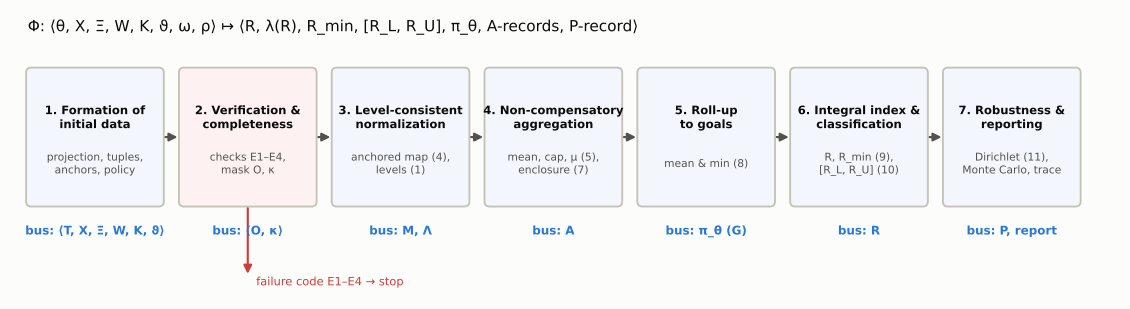

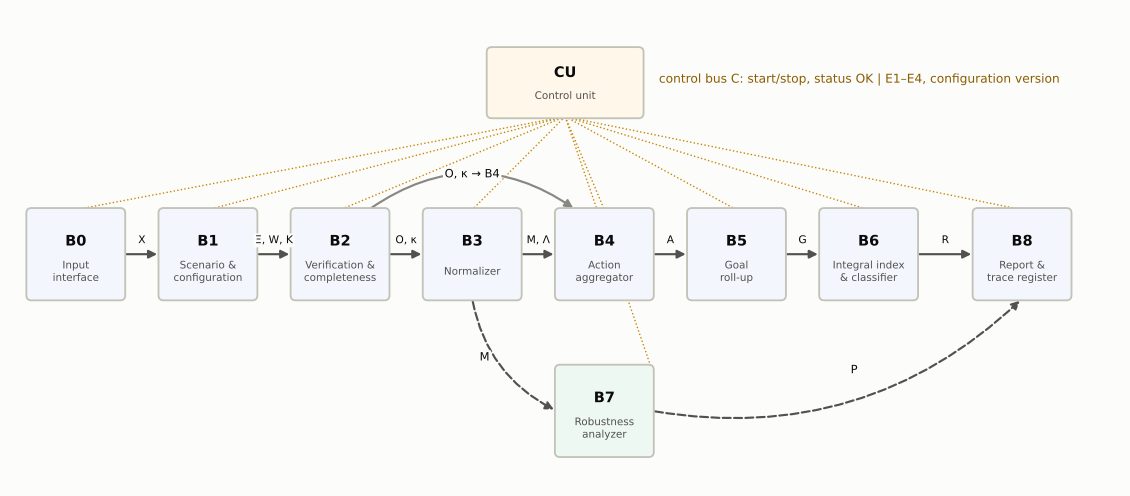

In [6]:
fig = diagrams.method_stages(); plt.show()
fig = diagrams.structural_model(); plt.show()

In [7]:
pd.DataFrame([{"bus": b, "from": s, "to": d, "quantities": q} for b, (s, d, q) in BUSES.items()])

,bus,from,to,quantities
0,X,B0,B1,physical values x and missing-value flags
1,XiWK,B1,B2,"class tables, polarity, weights, core set, thr..."
2,O,B2,"B3,B4",observation mask and completeness
3,M,B3,"B4,B7",normalized scores and their levels
4,A,B4,B5,"action records S, c, mu, L, U, flags"
5,G,B5,B6,"goal scores (mean, min) and enclosures"
6,R,B6,B8,"integral index, level, weakest link, enclosure..."
7,P,B7,B8,robustness statistics and level shares
8,C,CU,B0-B8,"control signals, status, configuration version"


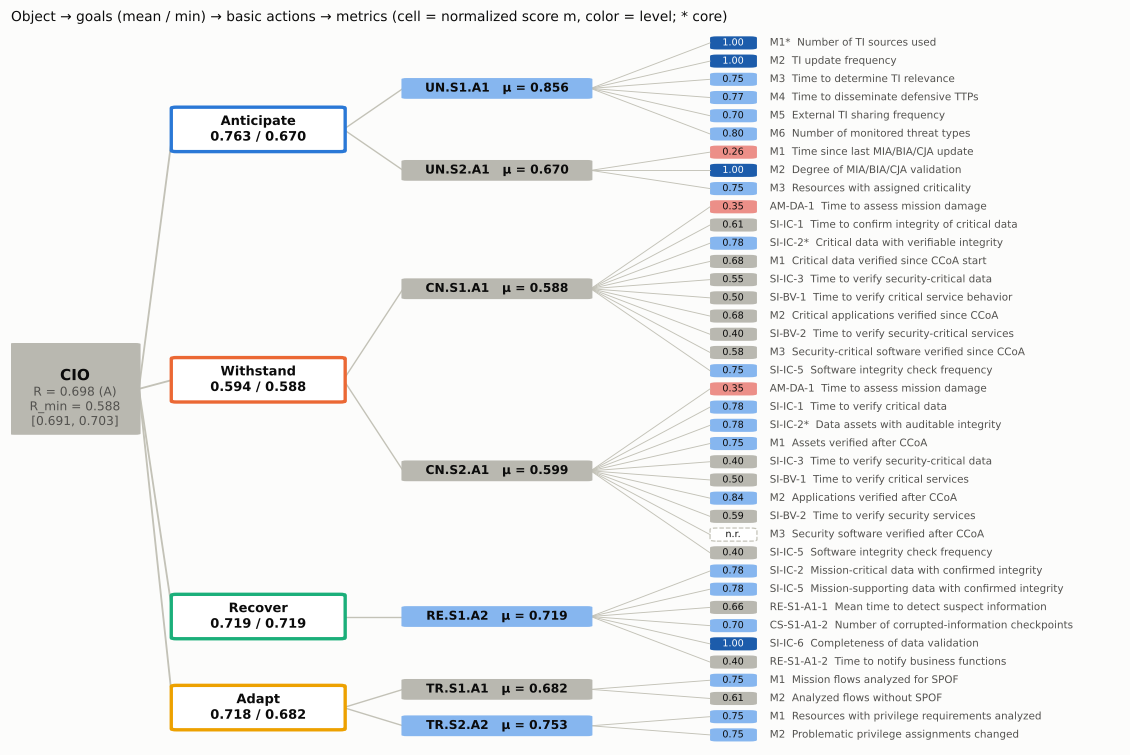

In [8]:
fig = diagrams.hierarchy(assess(cfg, e1_values(), robust=False)); plt.show()

## 4. Відтворення опублікованих значень CRTM (Table 5)
Допуск 0.0005 — половина одиниці останнього опублікованого знака.

In [9]:
rep = ex.reproduction(cfg)
df = pd.DataFrame(rep["rows"]); df["system"] = df["system"].round(4); df["abs_diff"] = df["abs_diff"].round(5)
print(f"відтворено {rep['n_ok']}/{rep['n']}, max |Δ| = {rep['max_abs_diff']:.5f}; оболонка CN.S2.A1: {rep['enclosure']['ok']}; "
      f"інтегральний індекс vs ручний розрахунок: {rep['integral_system']:.4f} vs {rep['integral_hand']:.4f}")
df

відтворено 15/15, max |Δ| = 0.00050; оболонка CN.S2.A1: True; інтегральний індекс vs ручний розрахунок: 0.6983 vs 0.6985


,element,kind,published,system,kappa,level,abs_diff,ok
0,UN.S1.A1,action,0.856,0.8558,1.0,AA,0.00017,True
1,UN.S2.A1,action,0.670,0.6702,1.0,A,0.00016,True
2,CN.S1.A1,action,0.588,0.5885,1.0,A,0.00046,True
3,CN.S2.A1,action,0.599,0.5989,0.9,A,0.00007,True
4,RE.S1.A2,action,0.719,0.7192,1.0,AA,0.00017,True
5,TR.S1.A1,action,0.682,0.6817,1.0,A,0.00033,True
6,TR.S2.A2,action,0.753,0.7533,1.0,AA,0.00033,True
7,Goal ANT (mean),goal,0.763,0.7630,NaN,AA,0.00000,True
8,Goal ANT (min),goal,0.670,0.6702,NaN,A,0.00016,True
9,Goal WITH (mean),goal,0.594,0.5937,NaN,A,0.00030,True


Правило (12) проти опублікованої Table A1. Знайдено дві розбіжності (E2, UN.S1.A1, M3/M4: 102/142 у таблиці, 102.5/142.5 за правилом); за замовчуванням використовується опублікована таблиця, вплив на R < 0.0002:

In [10]:
from crtm_ois.scenarios import compare_rule_with_table
print(compare_rule_with_table(cfg))
rule = five_states(cfg, source="rule")
print("R(E2) table vs rule:", round(assess(cfg, st["E2"], robust=False).index, 5), round(assess(cfg, rule["E2"], robust=False).index, 5))

[{'state': 'E2', 'action': 'UN.S1.A1', 'metric': 'M3', 'table': 102.0, 'rule': 102.5}, {'state': 'E2', 'action': 'UN.S1.A1', 'metric': 'M4', 'table': 142.0, 'rule': 142.5}]
R(E2) table vs rule: 0.36445 0.3644


## 5. П’ять експериментів адекватності (Table 7, Fig. 5–6)

In [11]:
t0 = time.time(); adq = ex.adequacy(cfg, n=200_000); sw = ex.sweep(cfg)
tab = pd.DataFrame([{ "exp": e, "t": adq[e]["t"], "goals ANT/WITH/REC/AD": " / ".join(f"{adq[e]['goals_mean'][g]:.3f}" for g in GOALS),
    "R": round(adq[e]["R"], 3), "level": adq[e]["level_code"], "expected": lv.code(adq[e]["expected"]), "R_min": round(adq[e]["R_min"], 3),
    "[R_L, R_U]": f"[{adq[e]['R_L']:.3f}, {adq[e]['R_U']:.3f}]", "R̄ ± sd": f"{adq[e]['mc']['mean']:.3f} ± {adq[e]['mc']['sd']:.3f}",
    "shares": ", ".join(f"{k} {v:.1%}" for k, v in adq[e]["mc"]["shares"].items() if v > 0.0005), "vetoed": ", ".join(adq[e]["vetoed"]) or "—"}
    for e in ["E1", "E2", "E3", "E4", "E5"]])
print("порядок E4<E2<E1<E3<E5:", adq["_order_ok"], "| монотонність R:", sw["monotone_R"], "| перетини меж:",
      {k: round(v, 3) for k, v in sw["crossings"].items()}, f"| {time.time()-t0:.1f} c")
tab

порядок E4<E2<E1<E3<E5: True | монотонність R: True | перетини меж: {0.2: -0.864, 0.4: -0.42, 0.7: 0.005, 0.9: 0.645} | 0.8 c


,exp,t,goals ANT/WITH/REC/AD,R,level,expected,R_min,"[R_L, R_U]",R̄ ± sd,shares,vetoed
0,E1,0.0,0.763 / 0.594 / 0.719 / 0.718,0.698,A,A,0.588,"[0.691, 0.703]",0.696 ± 0.028,"A 54.4%, AA 45.6%",—
1,E2,-0.5,0.385 / 0.348 / 0.337 / 0.388,0.364,BA,BA,0.330,"[0.360, 0.373]",0.366 ± 0.011,"BA 99.8%, A 0.2%",—
2,E3,0.5,0.869 / 0.827 / 0.853 / 0.881,0.858,AA,AA,0.819,"[0.847, 0.860]",0.855 ± 0.015,AA 100.0%,—
3,E4,-1.0,0.000 / 0.000 / 0.000 / 0.000,0.000,C,C,0.000,"[0.000, 0.000]",0.000 ± 0.000,C 100.0%,"UN.S1.A1, CN.S1.A1, CN.S2.A1"
4,E5,1.0,1.000 / 1.000 / 1.000 / 1.000,1.000,H,H,1.000,"[0.987, 1.000]",1.000 ± 0.000,H 100.0%,—


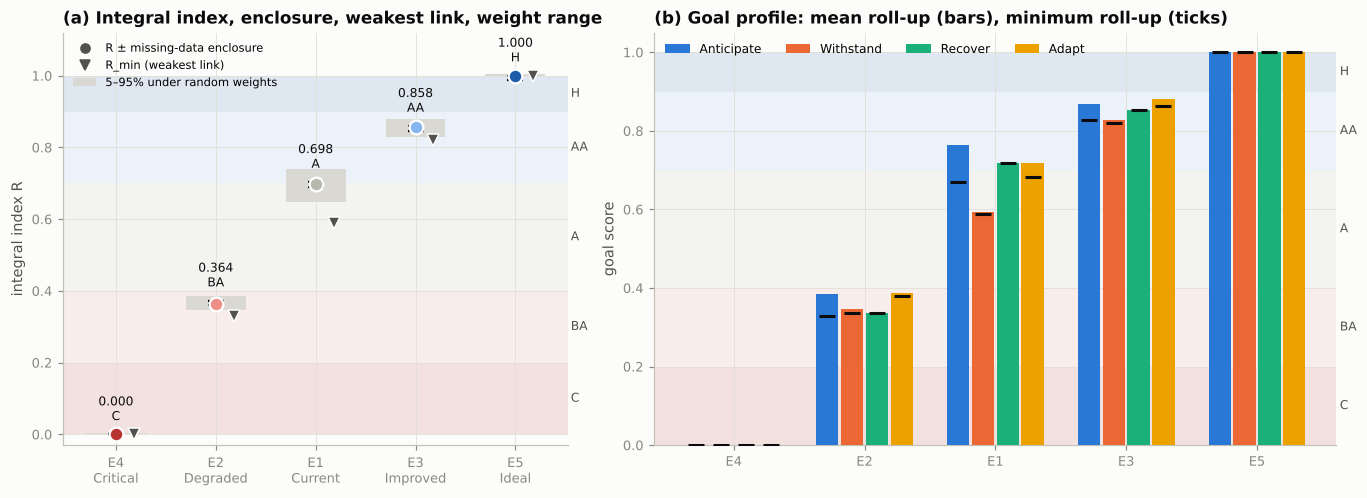

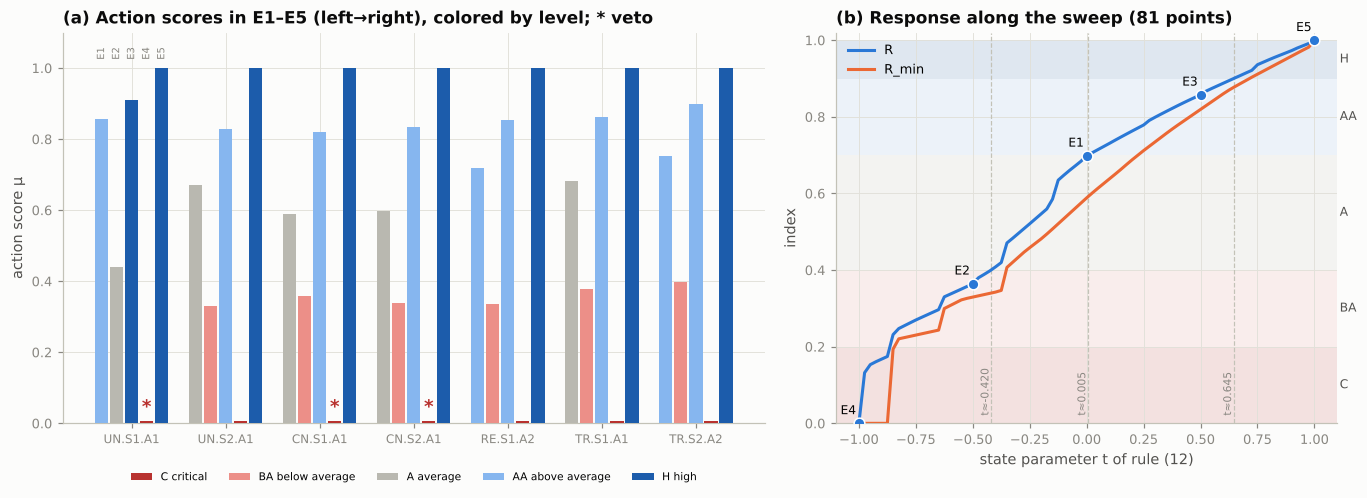

In [12]:
fig = charts.adequacy_figure(adq); plt.show()
fig = charts.actions_and_sweep(adq, sw, cfg); plt.show()

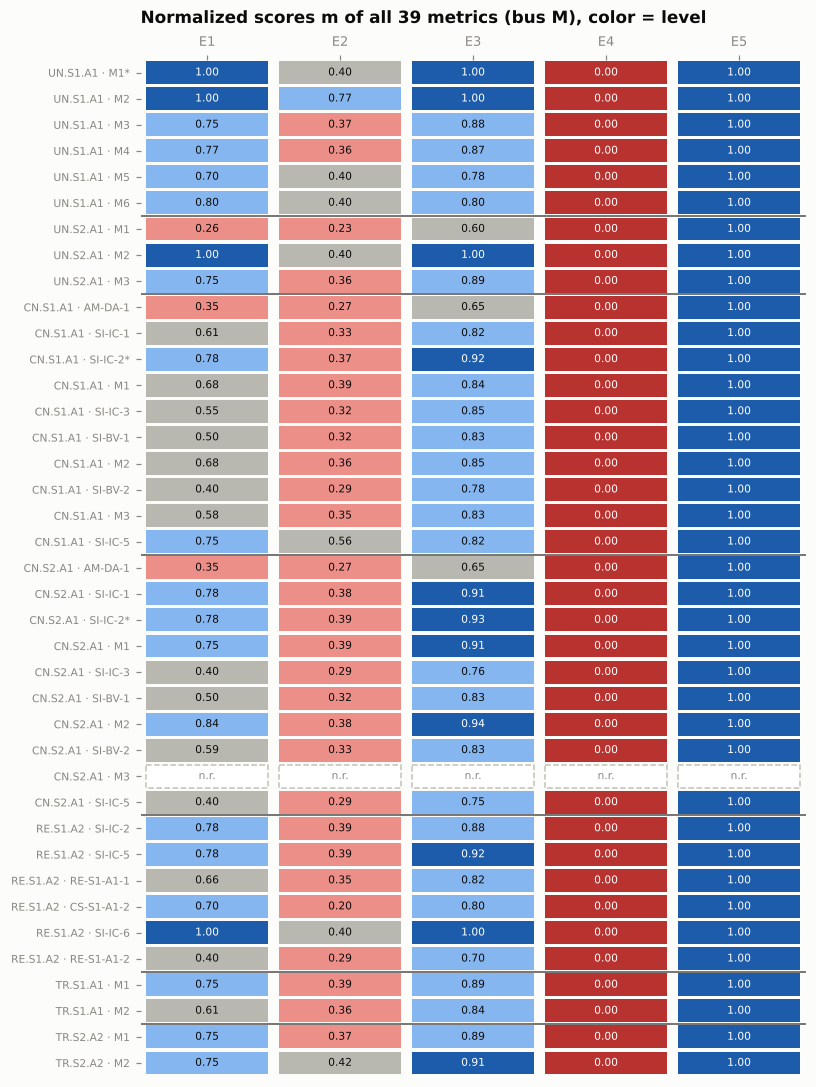

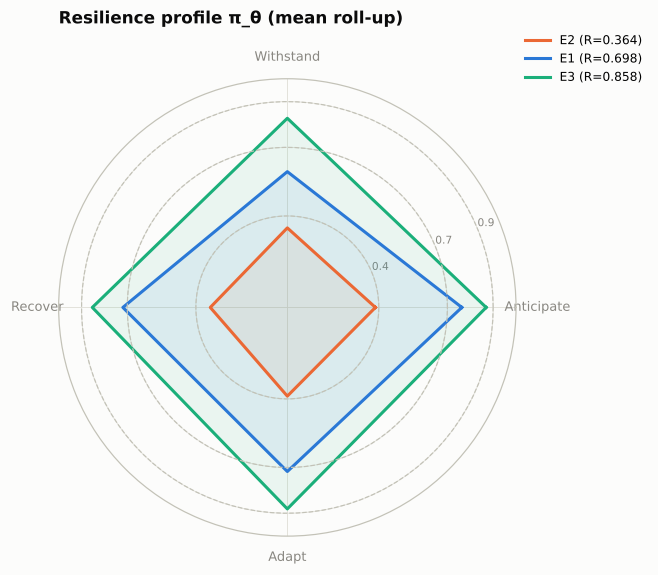

In [13]:
norms = {e: assess(cfg, x, robust=False).norm["M"] for e, x in st.items()}
fig = charts.metric_heatmap(adq, cfg, norms); plt.show()
fig = charts.goal_radar(adq); plt.show()

## 6. Робастність до ваг і некомпенсація (Fig. 7)

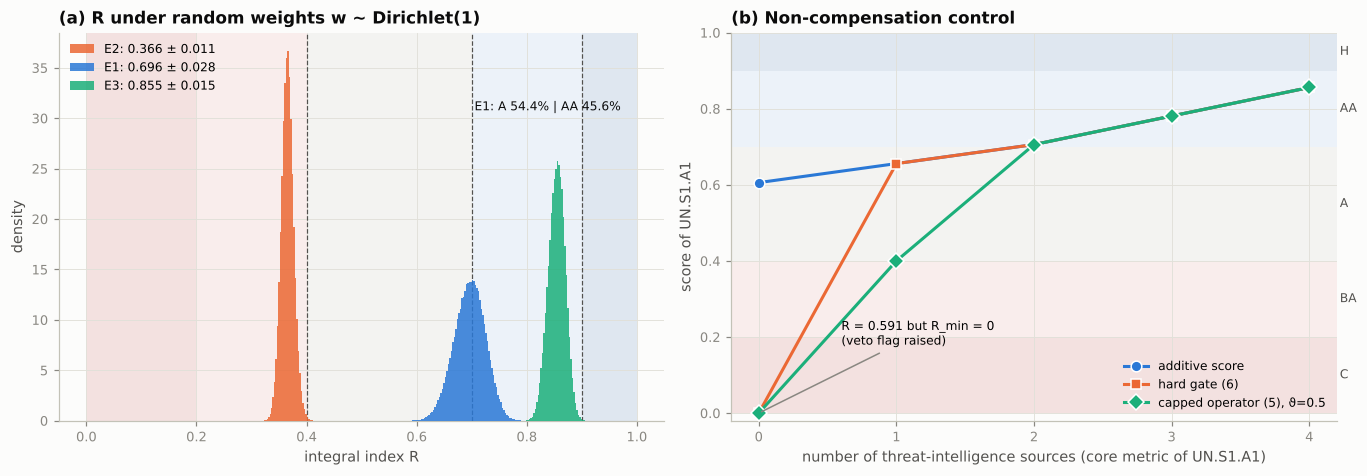

A      AA      BA     H
1.0 E1  54.4%   45.6%     NaN   NaN
    E2   0.2%     NaN   99.8%   NaN
    E3    NaN  100.0%     NaN  0.0%
4.0 E1  60.1%   39.9%     NaN   NaN
    E2    NaN     NaN  100.0%   NaN
    E3    NaN  100.0%     NaN   NaN

In [14]:
nc = ex.non_compensation(cfg)
fig = charts.robustness_and_noncomp(adq, nc); plt.show()
rb = ex.robustness_rho(cfg, n=200_000)
pd.DataFrame({(rho, e): {k: f"{v:.1%}" for k, v in d["shares"].items() if v > 0} for rho, dd in rb.items() for e, d in dd.items()}).T

In [15]:
pd.DataFrame({op: [round(v, 3) for v in nc[op]["action"]] for op in ("additive", "hard", "capped")},
             index=pd.Index(nc["sources"], name="TI sources")).assign(R_capped=[round(v, 3) for v in nc["capped"]["R"]],
                                                                     R_min_capped=nc["capped"]["R_min"])

,additive,hard,capped,R_capped,R_min_capped
TI sources,,,,,
0,0.606,0.000,0.000,0.591,0.000000
1,0.656,0.656,0.400,0.641,0.400000
2,0.706,0.706,0.706,0.680,0.588458
3,0.781,0.781,0.781,0.689,0.588458
4,0.856,0.856,0.856,0.698,0.588458


## 7. Агентний шар: блоки B0–B8 і CU як агенти на шині повідомлень
Кожен блок структурної моделі — агент, що підписаний на свої вхідні шини (топіки) і публікує вихідну шину.
Блок спрацьовує, коли для одного прогону (correlation id) надійшли всі його входи. Результат команди агентів
збігається з `assess` до 1e-12; відмова B2 зупиняє ланцюг (CU публікує `stop`).

In [16]:
from crtm_ois.agents.bus import MessageBus
from crtm_ois.agents.blocks import build_block_team
bus = MessageBus(); reports = []
bus.subscribe("report", lambda m: reports.append(m.payload))
ref, cu, blocks = build_block_team(bus, cfg, mc_samples=20_000)
for e, x in st.items():
    cu.start(x)
    print(e, f"agents R = {reports[-1]['R']:.6f}", f"| CU/assess R = {assess(cfg, x, robust=False).index:.6f}", "| level", reports[-1]["level_code"])
c = cu.start({**e1_values(), ("UN.S1.A1", "M1"): None})       # ключова метрика відсутня
print("run", c, "→", cu.failures[c])
print("повідомлень на шині:", len(bus.log), "| статуси прогону 1:", cu.status[1])

E1 agents R = 0.698340 | CU/assess R = 0.698340 | level A
E2 agents R = 0.364452 | CU/assess R = 0.364452 | level BA
E3 agents R = 0.857606 | CU/assess R = 0.857606 | level AA
E4 agents R = 0.000000 | CU/assess R = 0.000000 | level C
E5 agents R = 1.000000 | CU/assess R = 1.000000 | level H
run 6 → {'status': 'E3', 'block': 'B2', 'detail': 'core metric UN.S1.A1.M1 is missing'}
повідомлень на шині: 108 | статуси прогону 1: [('B0', 'OK'), ('B1', 'OK'), ('B2', 'OK'), ('B3', 'OK'), ('B4', 'OK'), ('B7', 'OK'), ('B5', 'OK'), ('B6', 'OK'), ('B8', 'OK')]


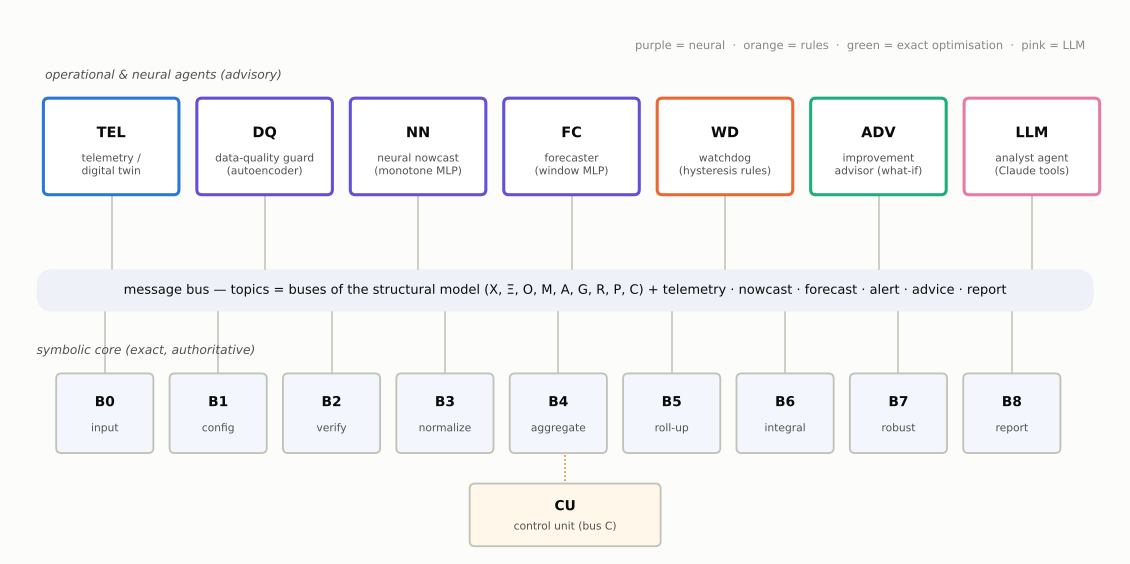

In [17]:
fig = diagrams.agent_topology(); plt.show()

## 8. Нейросурогат: монотонна MLP проти необмеженої
Мережа навчається відображенню «сирі вимірювання → (R, R_min)» на станах, згенерованих точною системою.
У монотонній мережі всі ваги параметризовано як softplus(v) ≥ 0, тож R̂ не спадає за жодною метрикою — нейронний аналог
критерію адекватності (iii). Сурогат лише дорадчий: на межі рівнів (E1 = 0.698) він помиляється, тому вердикт видає точна система.

monotone       params= 4706  MAE(R)=0.0129  MAE(R_min)=0.0428  level acc=94.7%  monotonicity violations=0.0%  (9 c)


unconstrained  params= 4706  MAE(R)=0.0106  MAE(R_min)=0.0251  level acc=95.7%  monotonicity violations=3.4%  (9 c)
E1 neural R̂=0.701 (AA)  exact R=0.698 (A)
E2 neural R̂=0.374 (BA)  exact R=0.364 (BA)
E3 neural R̂=0.859 (AA)  exact R=0.858 (AA)
E4 neural R̂=0.001 (C)  exact R=0.000 (C)
E5 neural R̂=0.984 (H)  exact R=1.000 (H)


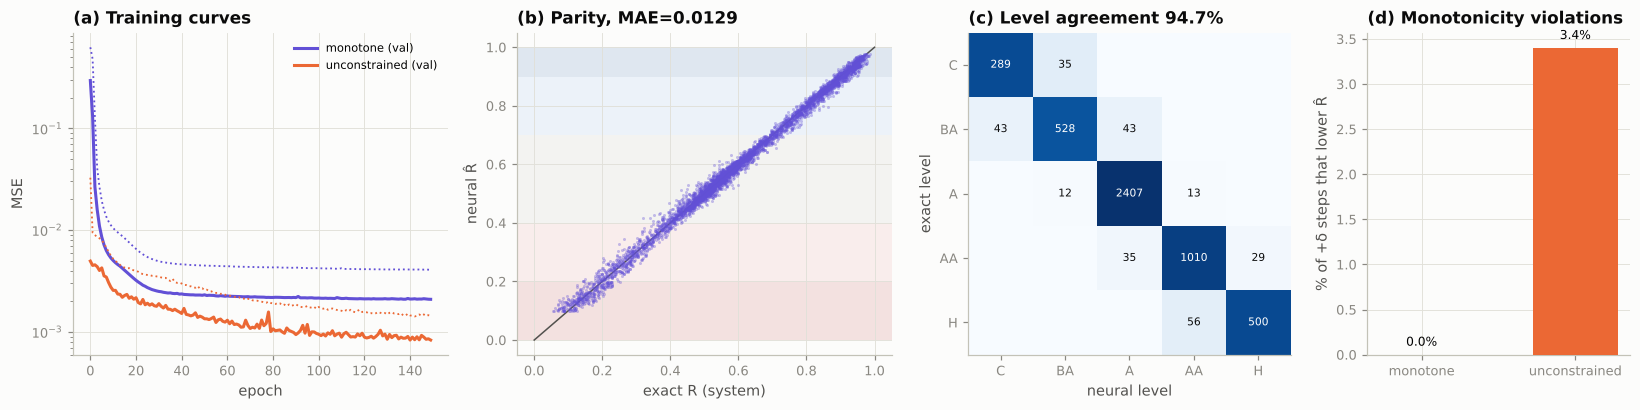

In [18]:
from crtm_ois.neural.models import NeuralSurrogate
nets, evals, surs = {}, {}, {}
for name, mono in (("monotone", True), ("unconstrained", False)):
    t0 = time.time(); s = NeuralSurrogate(cfg, monotone=mono).fit(n=30_000, epochs=150)
    surs[name], nets[name], evals[name] = s, s.net, s.evaluate()
    print(f"{name:14s} params={s.net.n_params():5d}  MAE(R)={evals[name]['mae_R']:.4f}  MAE(R_min)={evals[name]['mae_Rmin']:.4f}  "
          f"level acc={evals[name]['level_accuracy']:.1%}  monotonicity violations={evals[name]['monotone_violations']:.1%}  ({time.time()-t0:.0f} c)")
for e in st:
    p = surs["monotone"].predict_sheet(st[e]); exact = assess(cfg, st[e], robust=False)
    print(e, f"neural R̂={p['R']:.3f} ({lv.code(p['level'])})  exact R={exact.index:.3f} ({exact.R['level_code']})")
fig = charts.surrogate_figure(evals, nets); plt.show()

Градієнт сурогату дає миттєву карту чутливості (∂R̂/∂позиція метрики) — використовується для швидкого відбору кандидатів перед точним what-if:

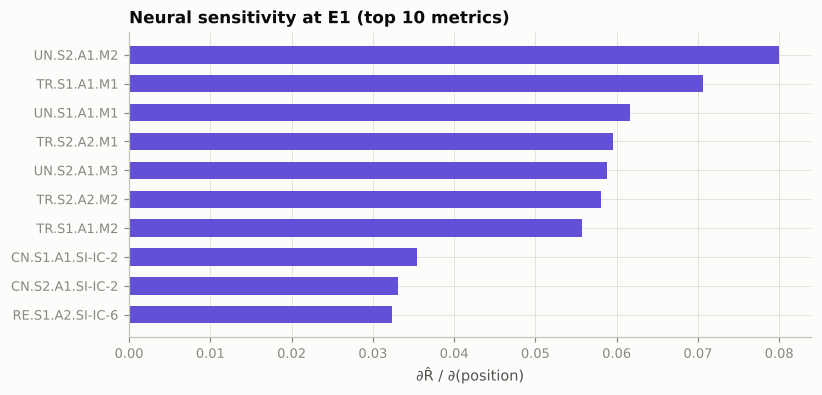

In [19]:
sens = surs["monotone"].sensitivity(e1_values())
top = sorted(sens.items(), key=lambda kv: -kv[1])[:10]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh([f"{a}.{m}" for (a, m), _ in top][::-1], [v for _, v in top][::-1], color="#6250d6", height=0.6)
ax.set_xlabel("∂R̂ / ∂(position)"); ax.set_title("Neural sensitivity at E1 (top 10 metrics)"); plt.show()

## 9. Цифровий двійник і мультиагентний центр стійкості
Синтетичний двійник процесингового центру генерує телеметрію 39 метрик (інцидент фішингу, відмова постачальника TI,
програма покращення) з вадами сенсорів (пропуски, сплески, «залиплі» значення).

Агенти: **TEL** (телеметрія) → **DQ** (автоенкодер + правило персистентності для ключових метрик) → **CU/B0–B8** (точний вердикт)
→ **FC** (нейропрогноз на 6 тактів) → **WD** (сторож з гістерезисом) → **ADV** (радник). **NN** дає нейронний nowcast паралельно.

навчання нейроагентів: 12 c


220 тактів: 1.2 c, повідомлень на шині: 5149
DQ: recall=87%, precision=70% | forecast MAE=0.0182 | nowcast MAE=0.0097


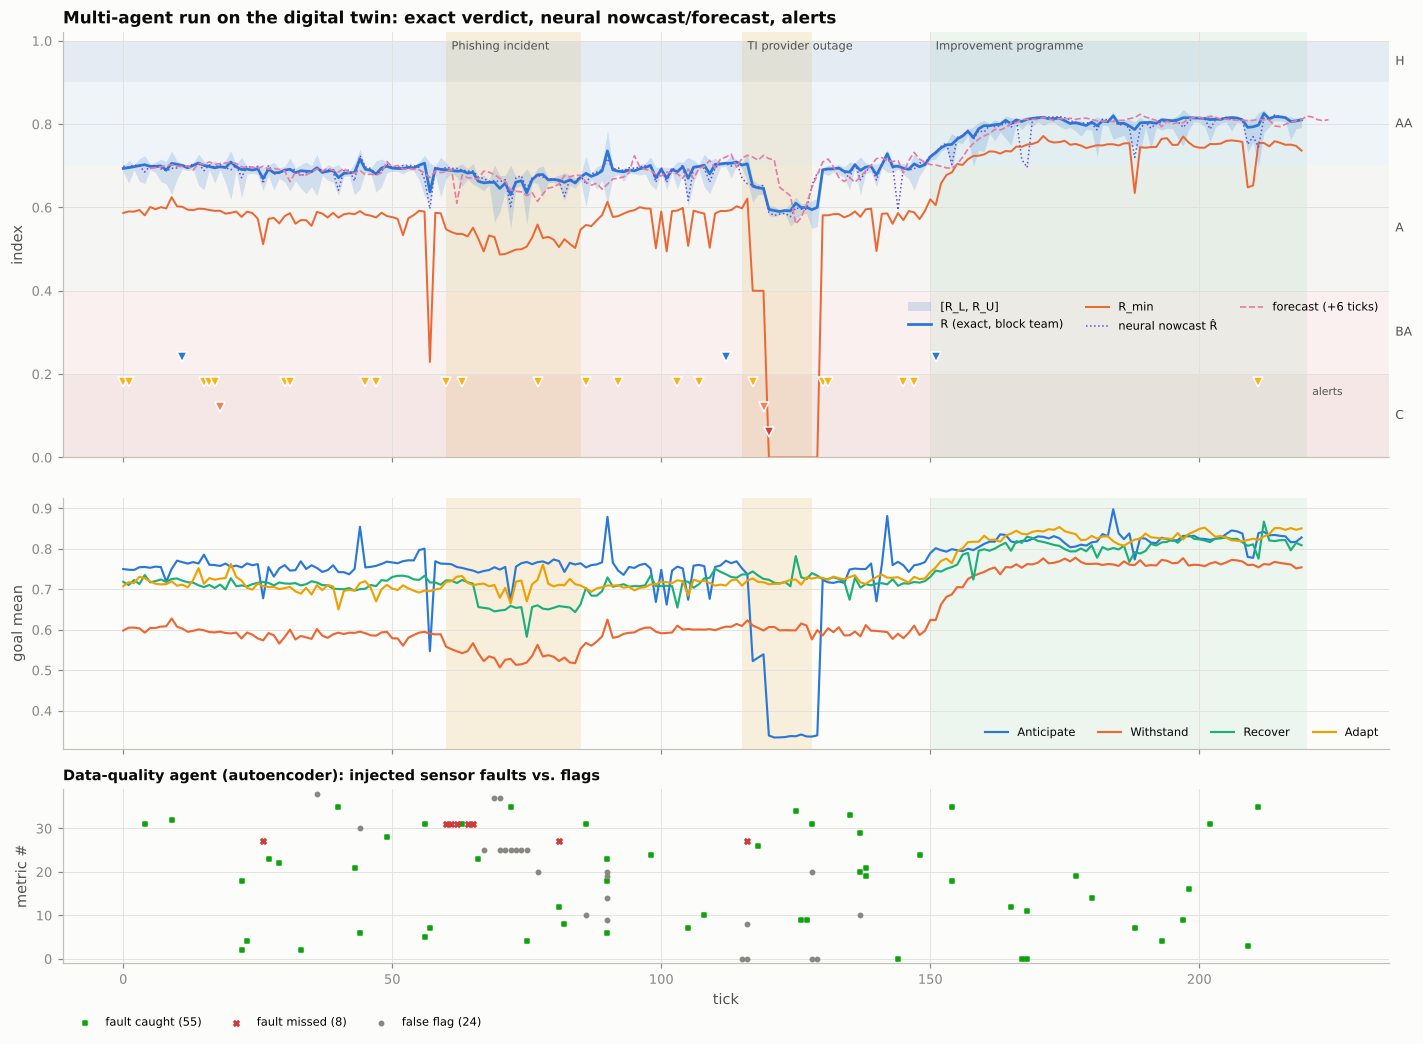

In [20]:
from crtm_ois.agents.ops import ResilienceOperationsCenter, train_neural_agents
t0 = time.time(); sur, ae, fc = train_neural_agents(cfg); print(f"навчання нейроагентів: {time.time()-t0:.0f} c")
oc = ResilienceOperationsCenter(cfg, seed=3, surrogate=sur, ae=ae, forecaster=fc)
t0 = time.time(); h = oc.run(220); print(f"220 тактів: {time.time()-t0:.1f} c, повідомлень на шині: {len(oc.bus.log)}")
F, Fl = h["faults"] >= 2, h["flags"]
print(f"DQ: recall={(F & Fl).sum()/F.sum():.0%}, precision={(F & Fl).sum()/Fl.sum():.0%} | "
      f"forecast MAE={np.nanmean(np.abs(h['forecast'][12:-6]-h['R'][18:])):.4f} | nowcast MAE={np.mean(np.abs(h['nowcast']-h['R'])):.4f}")
fig = charts.twin_dashboard(h, cfg); plt.show()

In [21]:
pd.DataFrame(h['alerts'])[['tick', 'severity', 'kind', 'text']]

,tick,severity,kind,text
0,0,warning,weights,verdict sensitive to weights (top share 61%)
1,1,warning,unstable,missing-data enclosure crosses a level boundary
2,11,info,level_rise,level A -> AA
3,15,warning,weights,verdict sensitive to weights (top share 57%)
4,16,warning,unstable,missing-data enclosure crosses a level boundary
5,17,warning,forecast_drop,forecast R=0.698 in 6 ticks (level A)
6,18,serious,level_drop,level AA -> A
7,30,warning,weights,verdict sensitive to weights (top share 67%)
8,31,warning,unstable,missing-data enclosure crosses a level boundary
9,45,warning,weights,verdict sensitive to weights (top share 63%)


In [22]:
pd.DataFrame(h['advice'])

,tick,trigger,top
0,18,level_drop,"[(RE.S1.A2.CS-S1-A1-2, 0.0125), (RE.S1.A2.RE-S..."
1,119,level_drop,"[(UN.S1.A1.M1, 0.0351), (RE.S1.A2.CS-S1-A1-2, ..."
2,120,veto,"[(UN.S1.A1.M1, 0.05), (RE.S1.A2.CS-S1-A1-2, 0...."


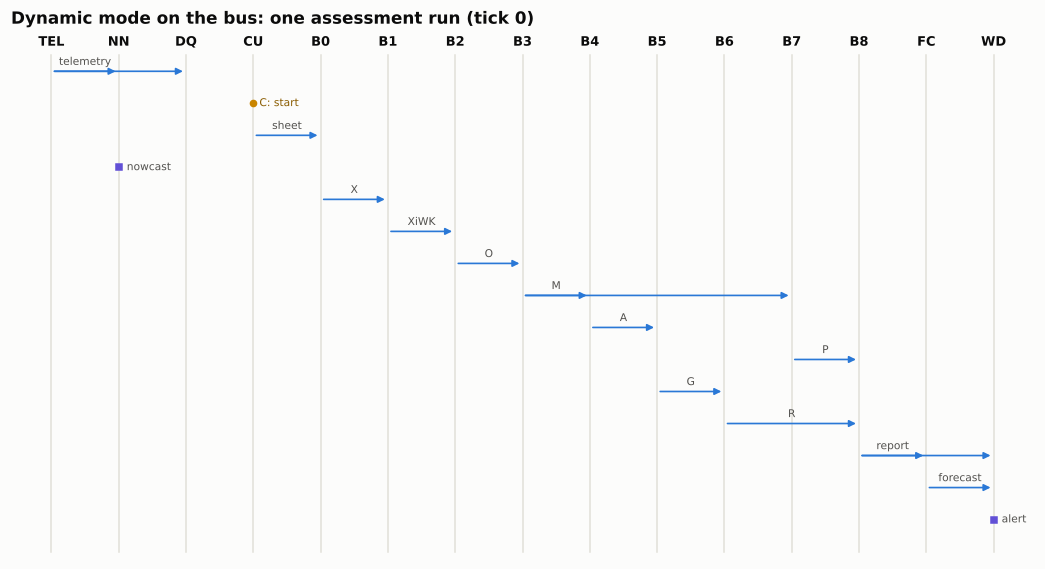

In [23]:
fig = diagrams.sequence_chart(oc.bus, corr=1, title='Dynamic mode on the bus: one assessment run (tick 0)'); plt.show()

## 10. Агент-радник: точний what-if і план покращення
Кандидати діють на **фізичні вимірювання**: спільне вимірювання AM-DA-1 одночасно змінює обидві дії цілі Withstand
(горизонтальна залежність, §4.3). Мета плану — стійкий вердикт, тобто гарантований індекс R_L вище межі рівня.

,source,from,to,dR,dR_L,dR_min
0,RE.S1.A2.RE-S1-A1-2,[30.0],[15.0],0.0125,0.0125,0.0
1,RE.S1.A2.CS-S1-A1-2,[4.0],[6.0],0.0125,0.0125,0.0
2,TR.S1.A1.M1,[80.0],[91.0],0.0092,0.0092,0.0
3,TR.S2.A2.M1,[80.0],[91.0],0.0092,0.0092,0.0
4,TR.S2.A2.M2,[75.0],[86.0],0.0092,0.0092,0.0
5,UN.S2.A1.M3,[80.0],[91.0],0.0061,0.0061,0.0
6,UN.S2.A1.M1,[705600.0],[525600.0],0.0060,0.0060,0.0
7,TR.S1.A1.M2,[60.0],[66.0],0.0056,0.0056,0.0
8,RE.S1.A2.SI-IC-2,[90.0],[96.0],0.0050,0.0050,0.0
9,RE.S1.A2.SI-IC-5,[85.0],[91.0],0.0050,0.0050,0.0


пропущене значення: [{'metric': ('CN.S2.A1', 'M3'), 'R_if_critical': 0.6908530634475076, 'R_if_ideal': 0.7033530634475076, 'value_needed': 82.625}]


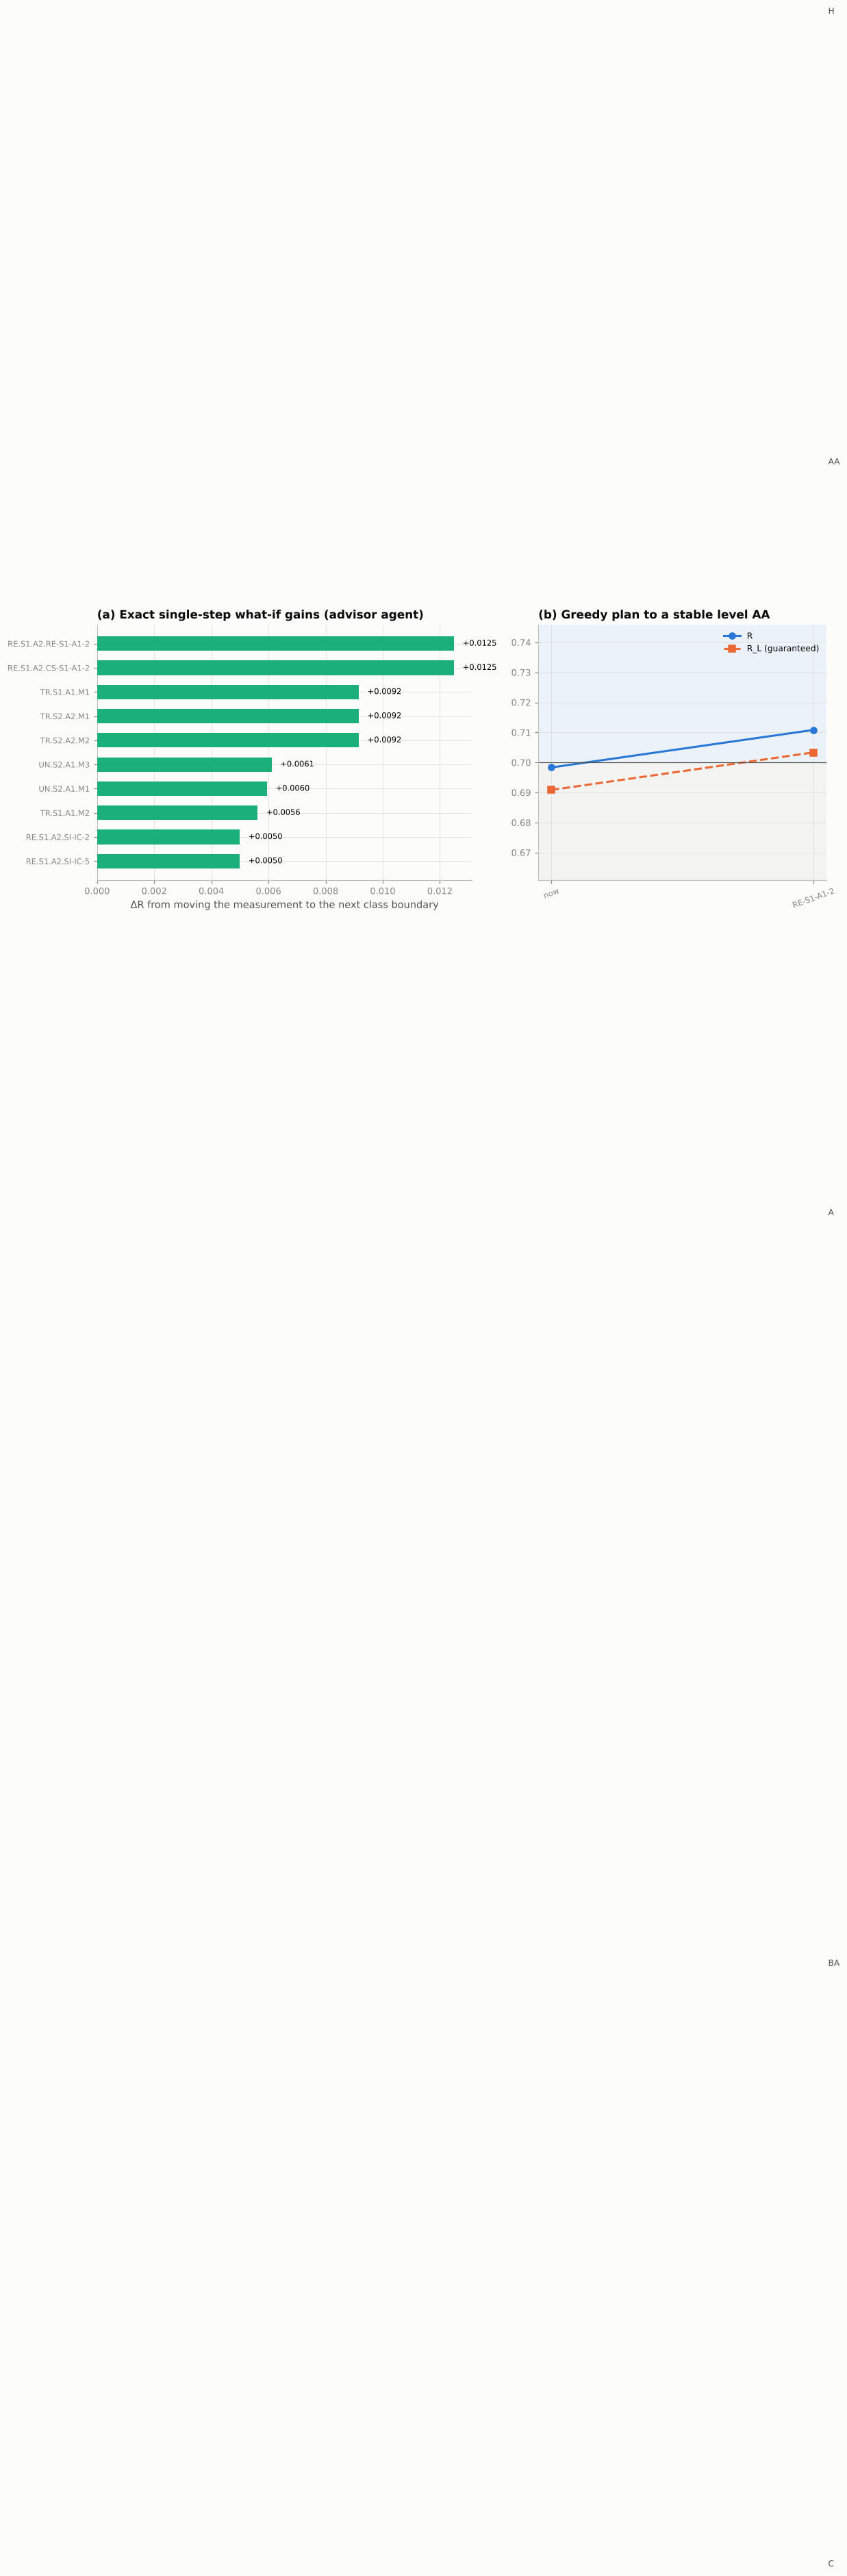

In [24]:
from crtm_ois.agents.advisor import ImprovementAdvisor
adv = ImprovementAdvisor(cfg)
cands = adv.candidates(e1_values()); plan = adv.plan(e1_values())
display(pd.DataFrame(cands)[["source", "from", "to", "dR", "dR_L", "dR_min"]].head(10).round(4))
print("пропущене значення:", adv.missing_value_thresholds(e1_values()))
fig = charts.advisor_figure(cands, plan); plt.show()

## 11. LLM-аналітик: система як набір інструментів
`ResilienceToolbox` надає шість інструментів з JSON-схемами (`load_state`, `assess_current`, `explain_action`, `what_if`,
`recommend`, `get_trace`). `ClaudeAnalyst` запускає цикл tool use Claude API (SDK `tool_runner`, модель `claude-opus-5-5`,
адаптивне мислення, серверні fallbacks), і кожне число у відповіді береться з інструментів, тобто з точної системи.
`OfflineAnalyst` використовує ті самі інструменти без мережі.

In [25]:
from crtm_ois.agents.llm import ResilienceToolbox, OfflineAnalyst, ClaudeAnalyst
tb = ResilienceToolbox(cfg)
print(json.dumps([s["name"] + ": " + s["description"][:70] for s in tb.schemas()], indent=1, ensure_ascii=False))
print(json.dumps(tb.what_if("CN.S1.A1", "AM-DA-1", 90), ensure_ascii=False))

[
 "load_state: Load one of the input states E1..E5 (current, degraded, improved, crit",
 "assess_current: Run the seven-stage assessment on the current sheet; returns R, level,",
 "explain_action: Explain one basic action at bus level (values, class tables, normalize",
 "what_if: Change one measurement (null = not reported) and compare the verdict b",
 "recommend: Greedy improvement plan to reach a target level with a stable verdict.",
 "get_trace: Return the content of one bus of the last run."
]
{"changed": "CN.S1.A1.AM-DA-1", "from": 210.0, "to": 90, "shared_with": ["CN.S2.A1.AM-DA-1"], "R": [0.6983, 0.7076], "level": ["A", "AA"], "R_min": [0.5885, 0.6235], "enclosure_after": [0.6996, 0.7121], "vetoed_after": []}


In [26]:
from IPython.display import Markdown
Markdown(OfflineAnalyst(tb, lang='ua').report('E1'))

## Вердикт: R = 0.698 — рівень «середній» (A)
- Найслабша ланка R_min = 0.589 (A), дія CN.S1.A1; найслабша ціль — Withstand.
- Оболонка через пропущені дані: [0.691, 0.703] — перетинає межу рівнів, вердикт НЕ стабільний.
- Чутливість до ваг (Dirichlet ρ=1.0): A 54.5%, AA 45.5%.

### Чому CN.S1.A1 найслабша
- AM-DA-1 Time to assess mission damage: x = 210.0 min → m = 0.350 (BA)
- SI-BV-2 Time to verify security-critical services: x = 55.0 min → m = 0.400 (A)
- SI-BV-1 Time to verify critical service behavior: x = 40.0 min → m = 0.500 (A)

### План покращення до рівня AA (досягається)
1. RE.S1.A2.RE-S1-A1-2 → [15.0]: R = 0.711, R_L = 0.703
- Пропущений показник CN.S2.A1.M3: за його звітування R ∈ [0.691, 0.703]; для рівня AA потрібне значення ≥ 82.625.

_Дані сценарію ілюстративні; результат верифікує реалізацію, а не польову валідність._

In [27]:
import os
if os.environ.get("ANTHROPIC_API_KEY"):
    analyst = ClaudeAnalyst(ResilienceToolbox(cfg))
    print(analyst.ask("Оціни поточний стан E1 процесингового центру: чи стабільний вердикт і що покращити першочергово?"))
else:
    print("ANTHROPIC_API_KEY не задано — пропускаємо виклик Claude (див. OfflineAnalyst вище).")

ANTHROPIC_API_KEY не задано — пропускаємо виклик Claude (див. OfflineAnalyst вище).


## 12. Калібрування ваг цілей за експертними рівнями (майбутня робота §4.5)
Синтетична панель «експертів» оцінює 300 об’єктів, неявно зважуючи цілі як (0.15, 0.40, 0.30, 0.15).
Диференційовна порядкова логістична модель відновлює ω; узгодженість вимірюємо квадратично зваженою каппою Коена.

learned ω = [0.136 0.411 0.296 0.157] | κw equal = 0.713 | κw learned = 0.829


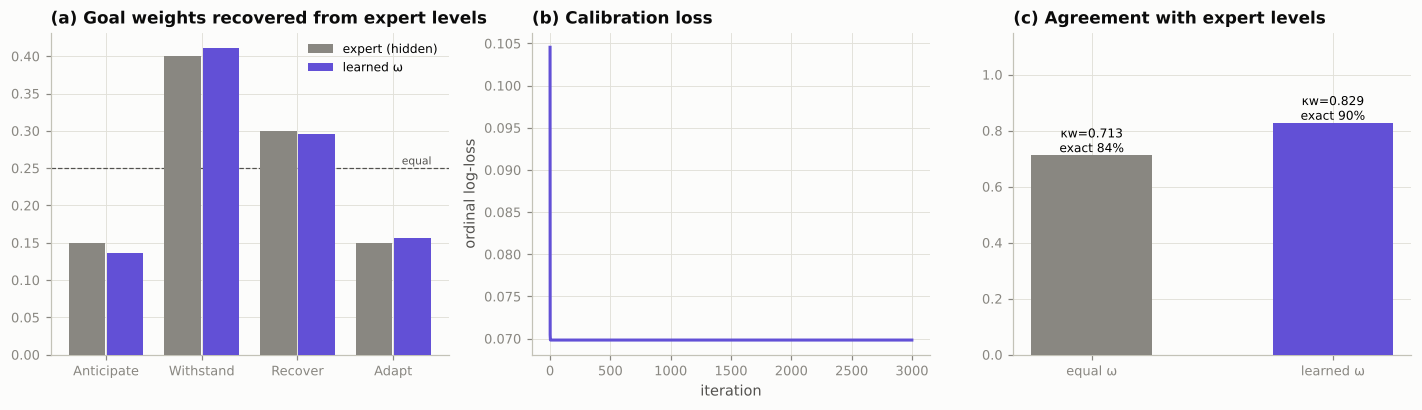

In [28]:
from crtm_ois.neural.models import GoalWeightCalibrator, synthetic_expert_panel, quadratic_kappa
G, expert = synthetic_expert_panel(cfg, 300)
cal = GoalWeightCalibrator().fit(G, expert)
before, after = lv.levels(G.mean(1)), lv.levels(G @ cal.omega)
print("learned ω =", np.round(cal.omega, 3), "| κw equal =", round(quadratic_kappa(expert, before), 3), "| κw learned =", round(quadratic_kappa(expert, after), 3))
fig = charts.calibration_figure(cal, (0.15, 0.40, 0.30, 0.15), G, expert, before, after, cfg.goals); plt.show()

## 13. Підсумок і обмеження
* Точна система відтворює 15/15 опублікованих значень CRTM у межах 0.0005, призначає очікувані рівні E1–E5 у правильному
  порядку, монотонна вздовж розгортки, накладає вето у E4 і звітує про пропуски оболонкою; частки за вагами E1 — 54.4 % / 45.6 %.
* Агентний шар реалізує структурну модель буквально (блоки = агенти, шини = топіки) і дає той самий результат.
* Нейрорішення дорадчі: монотонний сурогат не має порушень монотонності, але на межі рівнів помиляється; автоенкодер і правило
  персистентності відсіюють збої сенсорів до того, як вони спричинять хибне вето.
* Двійник, збої сенсорів і експертна панель синтетичні; польова валідність не встановлена.